# Result model

Predicting the game result in different model versions:
- v0 - class frequencies only
- v1 – ratings only
- v2 – pre-game context
- v3 – + opening (ECO)

In [1]:
import sys;

from sklearn.ensemble import RandomForestClassifier

sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

from src.features import build_features, time_split, fit_eco_vocab, apply_eco_vocab, calibration_table

In [2]:
df = pd.read_parquet("../data/clean.parquet")
df

,White,Black,Result,WhiteElo,BlackElo,TimeControl,ECO,Opening,Termination,event_type,utc_dt,game_id
0,cronopiodano,Magnataroniell,1-0,1708,1690,600+0,B10,Caro-Kann Defense: Euwe Attack,Time forfeit,Rated Classical tournament,2016-12-31 23:00:01,5utpphVs
1,MarlonTeixeira21,caguertti,0-1,1661,1614,300+0,B30,Sicilian Defense: Old Sicilian,Time forfeit,Rated Blitz tournament,2016-12-31 23:00:01,xUn53e0k
2,WinterSnowStorm,theivi,1-0,1968,1893,300+0,D35,"Queen's Gambit Declined: Exchange Variation, P...",Normal,Rated Blitz tournament,2016-12-31 23:00:01,Z5NSdZX4
3,walt_b,james205,0-1,1204,1461,300+0,C44,Ponziani Opening,Normal,Rated Blitz tournament,2016-12-31 23:00:01,RyirpGs3
4,bilbobalboa,PatzerGareBear13,1-0,1859,1772,600+0,C31,"King's Gambit Declined: Falkbeer, Milner-Barry...",Normal,Rated Classical tournament,2016-12-31 23:00:01,f1vd9VBf
...,...,...,...,...,...,...,...,...,...,...,...,...
10574244,arruru,michalisem,0-1,1816,1880,300+0,B21,Sicilian Defense: McDonnell Attack,Normal,Rated Blitz game,2017-01-31 22:59:56,VnBlWWrf
10574245,jozarov,agadmator,0-1,2214,1995,60+0,A31,"English Opening: Symmetrical Variation, Anti-B...",Time forfeit,Rated Bullet game,2017-01-31 22:59:56,gDXG5waf
10574246,asquithbom,glopezp25,0-1,1272,1442,600+0,B01,Scandinavian Defense: Main Line,Normal,Rated Classical game,2017-01-31 22:59:51,dSsRJyZe
10574247,TEBEPIZDA2,CaptainJaco,1-0,1455,1251,600+0,B20,Sicilian Defense: Bowdler Attack,Normal,Rated Classical game,2017-01-31 22:59:59,VAwHk00V


In [3]:
feat = build_features(df)
train, valid, test = time_split(feat)

vocab = fit_eco_vocab(train["eco"])
for part in (train, valid, test):
    part["eco"] = apply_eco_vocab(part["eco"], vocab)

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:<5} {len(part):>10,} games  {part['utc_dt'].min()} – {part['utc_dt'].max()}")

y_train = train["result"].to_numpy()
y_valid = valid["result"].to_numpy()

train  5,752,406 games  2016-12-31 23:00:00 – 2017-01-17 23:59:59
valid  2,402,538 games  2017-01-18 00:00:00 – 2017-01-24 23:59:59
test   2,419,305 games  2017-01-25 00:00:02 – 2017-01-31 22:59:59


In [4]:
CLASSES = [0, 1, 2]
SPEEDS = ["Bullet", "Blitz", "Classical"]

def multiclass_brier(y, proba):
    onehot = np.eye(len(CLASSES))[y]
    return np.mean(np.sum((proba - onehot) ** 2, axis=1))

def evaluate(name, y, proba, speed):
    rows = []
    groups = [("all", np.ones(len(y), dtype=bool))] + [(s, (speed == s).to_numpy()) for s in SPEEDS]
    for group, mask in groups:
        rows.append({
            "model": name,
            "speed": group,
            "log_loss": log_loss(y[mask], proba[mask], labels=CLASSES),
            "brier": multiclass_brier(y[mask], proba[mask]),
            "accuracy": (proba[mask].argmax(axis=1) == y[mask]).mean(),
        })
    return rows

results = []

In [5]:
# the share of each result in the training set
prior = train["result"].value_counts(normalize=True).sort_index().to_numpy()
print(dict(zip(["black_win", "draw", "white_win"], prior.round(3))))

proba_v0 = np.tile(prior, (len(valid), 1))
results += evaluate("v0_prior", y_valid, proba_v0, valid["speed"])

{'black_win': np.float64(0.463), 'draw': np.float64(0.041), 'white_win': np.float64(0.496)}


In [6]:
V1 = ["elo_diff", "elo_avg"]

model_v1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_v1.fit(train[V1], y_train)
assert list(model_v1.classes_) == CLASSES

proba_v1 = model_v1.predict_proba(valid[V1])
results += evaluate("v1_rating", y_valid, proba_v1, valid["speed"])

In [7]:
res = pd.DataFrame(results)
res.pivot(index="speed", columns="model", values="log_loss").round(4)

model,v0_prior,v1_rating
speed,,
Blitz,0.8408,0.7863
Bullet,0.8122,0.7225
Classical,0.8420,0.7852
all,0.8335,0.7691


In [8]:
res.round(4)

,model,speed,log_loss,brier,accuracy
0,v0_prior,all,0.8335,0.5373,0.4964
1,v0_prior,Bullet,0.8122,0.5299,0.4973
2,v0_prior,Blitz,0.8408,0.5399,0.4952
3,v0_prior,Classical,0.8420,0.5402,0.4976
4,v1_rating,all,0.7691,0.4805,0.6092
5,v1_rating,Bullet,0.7225,0.4515,0.6411
6,v1_rating,Blitz,0.7863,0.4918,0.5965
7,v1_rating,Classical,0.7852,0.4897,0.5995


In [9]:
print((proba_v1.argmax(axis=1) == 1).sum())

0


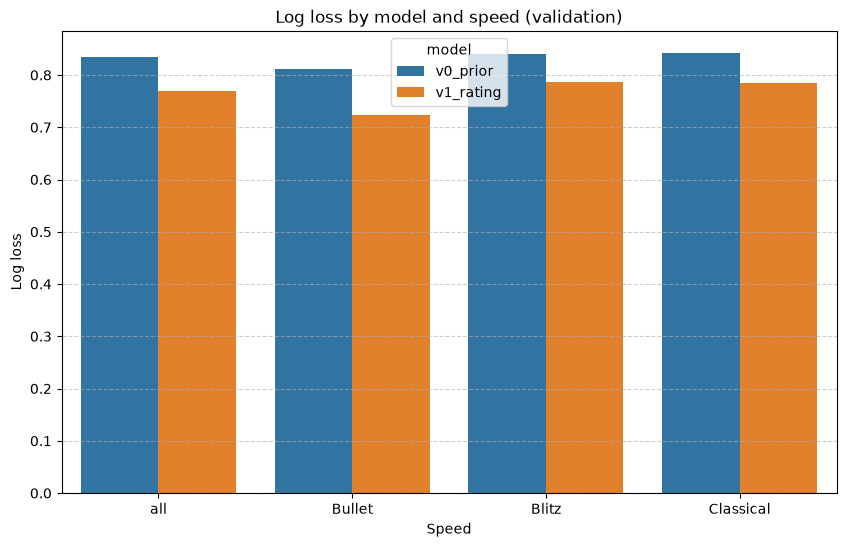

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=res,
    x="speed",
    y="log_loss",
    hue="model",
)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.title("Log loss by model and speed (validation)")
plt.xlabel("Speed")
plt.ylabel("Log loss")
plt.show()

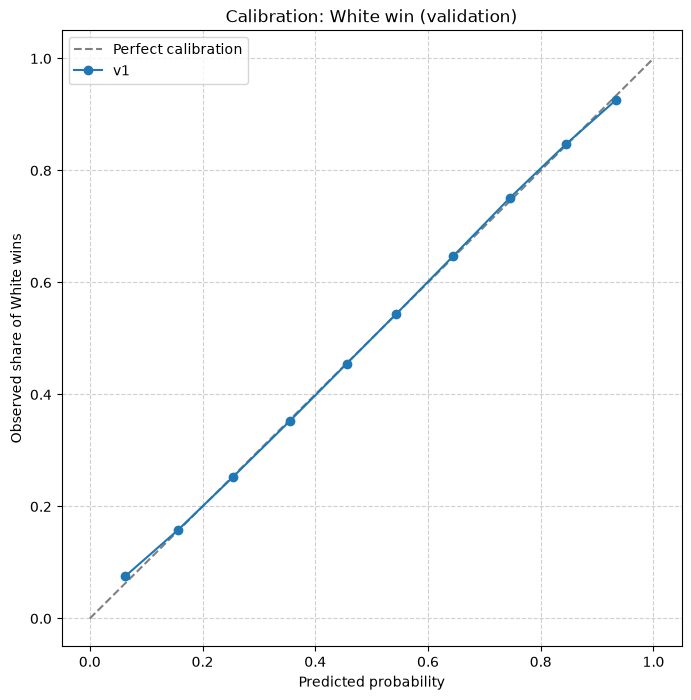

In [11]:
models = [("v1", proba_v1)]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

for name, proba in models:
    cal = calibration_table(proba[:, 2], y_valid, class_idx=2)
    plt.plot(cal["pred"], cal["observed"], "o-", label=name)

plt.grid(linestyle="--", alpha=0.6)
plt.title("Calibration: White win (validation)")
plt.xlabel("Predicted probability")
plt.ylabel("Observed share of White wins")
plt.legend()
plt.show()

## Results: v0 vs v1

**Ratings alone carry a clear signal.**
- Log loss drops from 0.834 (v0) to 0.769 (v1), a 7.7% improvement.
- Brier falls from 0.537 to 0.481.
- Accuracy rises from 49.6% to 60.9%. v0 always predicts a White win, so its accuracy equals the share of White wins.

**The gain is largest in Bullet**
- and smaller in Blitz and Classical. This is consistent with the EDA. Bullet has the widest pairings, so the rating difference is more often large and informative.

**v1 is well calibrated.**
- Observed White win rates follow the predicted ones across the whole range shown.

In [12]:
import lightgbm as lgb

V2 = ["elo_diff", "elo_avg", "base_time", "increment", "speed",
      "white_provisional", "black_provisional", "is_tournament"]

model_v2 = lgb.LGBMClassifier(
    objective="multiclass",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=500,
    n_jobs=-1,
    random_state=42,
    verbose=-1,
)

model_v2.fit(
    train[V2], y_train,
    eval_set=[(valid[V2], y_valid)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)
assert list(model_v2.classes_) == CLASSES

proba_v2 = model_v2.predict_proba(valid[V2])
results += evaluate("v2_context", y_valid, proba_v2, valid["speed"])

/home/igor/Projects/lichess-beyond-rating/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 0.766845
[200]	valid_0's multi_logloss: 0.766833
Early stopping, best iteration is:
[154]	valid_0's multi_logloss: 0.766829


In [13]:
imp = pd.Series(model_v2.booster_.feature_importance(importance_type="gain"), index=V2)
(imp / imp.sum()).sort_values(ascending=False).round(3)

elo_diff             0.955
elo_avg              0.015
base_time            0.010
white_provisional    0.007
black_provisional    0.005
speed                0.004
increment            0.004
is_tournament        0.001
dtype: float64

In [14]:
V2_RF = ["elo_diff", "elo_avg", "base_time", "increment",
         "white_provisional", "black_provisional", "is_tournament"]

model_v2_rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=500, max_samples=0.2, n_jobs=-1, random_state=42)

model_v2_rf.fit(train[V2_RF], y_train)
assert list(model_v2_rf.classes_) == CLASSES

proba_v2_rf = model_v2_rf.predict_proba(valid[V2_RF])
results += evaluate("v2_rf_rating", y_valid, proba_v2_rf, valid["speed"])

In [15]:
res = pd.DataFrame(results)
res.pivot(index="speed", columns="model", values="log_loss").round(4)

model,v0_prior,v1_rating,v2_context,v2_rf_rating
speed,,,,
Blitz,0.8408,0.7863,0.7852,0.7864
Bullet,0.8122,0.7225,0.7180,0.7221
Classical,0.8420,0.7852,0.7833,0.7846
all,0.8335,0.7691,0.7668,0.7688


In [16]:
res.round(4)

,model,speed,log_loss,brier,accuracy
0,v0_prior,all,0.8335,0.5373,0.4964
1,v0_prior,Bullet,0.8122,0.5299,0.4973
2,v0_prior,Blitz,0.8408,0.5399,0.4952
3,v0_prior,Classical,0.8420,0.5402,0.4976
4,v1_rating,all,0.7691,0.4805,0.6092
5,v1_rating,Bullet,0.7225,0.4515,0.6411
6,v1_rating,Blitz,0.7863,0.4918,0.5965
7,v1_rating,Classical,0.7852,0.4897,0.5995
8,v2_context,all,0.7668,0.4795,0.6104
9,v2_context,Bullet,0.7180,0.4495,0.6432


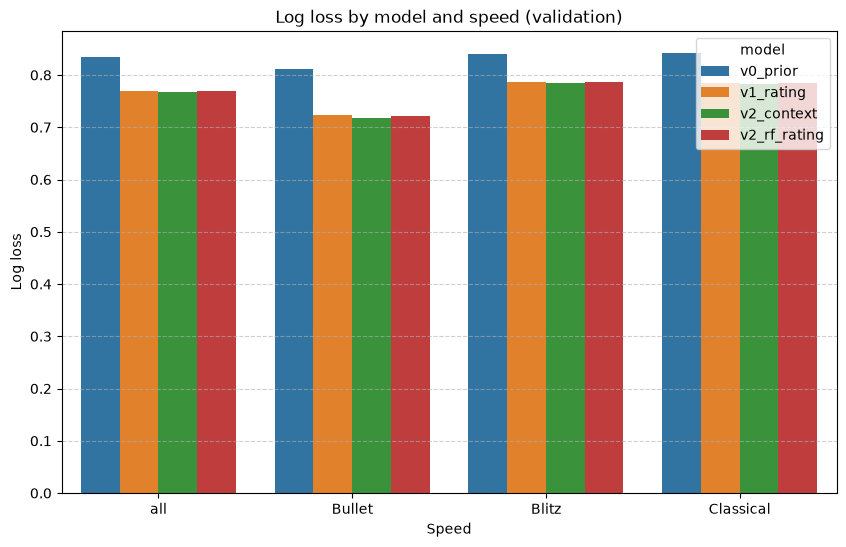

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=res,
    x="speed",
    y="log_loss",
    hue="model",
)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.title("Log loss by model and speed (validation)")
plt.xlabel("Speed")
plt.ylabel("Log loss")
plt.show()

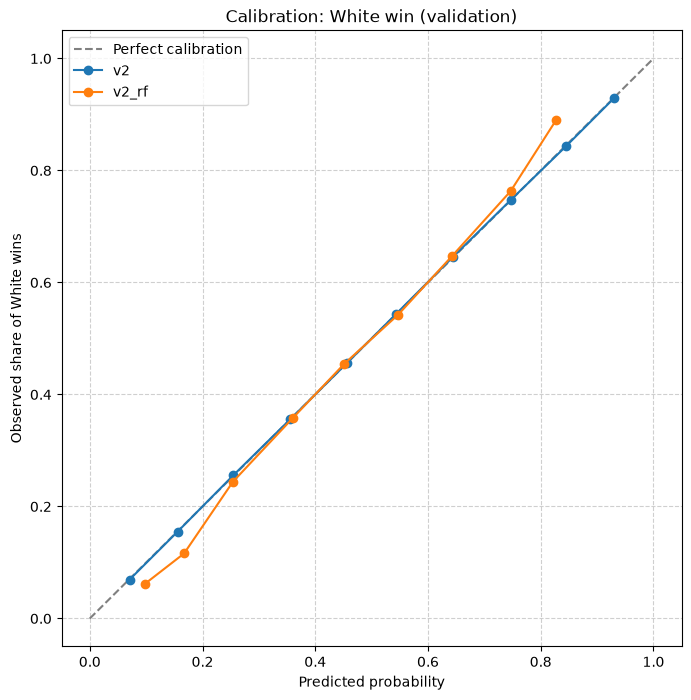

In [19]:
models = [("v2", proba_v2), ("v2_rf", proba_v2_rf)]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

for name, proba in models:
    cal = calibration_table(proba[:, 2], y_valid, class_idx=2)
    plt.plot(cal["pred"], cal["observed"], "o-", label=name)

plt.grid(linestyle="--", alpha=0.6)
plt.title("Calibration: White win (validation)")
plt.xlabel("Predicted probability")
plt.ylabel("Observed share of White wins")
plt.legend()
plt.show()

## Results: v1 vs v2

**Context adds little beyond ratings.**
- Log loss: from 0.7691 (v1) to 0.7668 (v2), a 0.30% improvement. The random forest with the same features stays at v1 level 0.7688.
- Brier: from 0.4805 (v1) to 0.4795 (v2).
- accuracy: from 60.92% (v1) to 61.04% (v2).
- `elo_diff` accounts for 95.5% of the model's total gain.

**v2 is well calibrated, the random forest is not.**
- v2 follows the diagonal across the whole range.
- The random forest pulls its predictions towards the middle: when it predicts 10–17%, White wins only 6–12% of such games. When it predicts about 83%, White wins about 89%. It also never predicts above about 83%.

In [20]:
V3 = ["elo_diff", "elo_avg", "base_time", "increment", "speed",
      "white_provisional", "black_provisional", "is_tournament", "eco"]

model_v3 = lgb.LGBMClassifier(
    objective="multiclass",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=500,
    n_jobs=-1,
    random_state=42,
    verbose=-1,
)

model_v3.fit(
    train[V3], y_train,
    eval_set=[(valid[V3], y_valid)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100),]
)
assert list(model_v3.classes_) == CLASSES

proba_v3 = model_v3.predict_proba(valid[V3])
results += evaluate("v3_context", y_valid, proba_v3, valid["speed"])

/home/igor/Projects/lichess-beyond-rating/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 0.76621
Early stopping, best iteration is:
[117]	valid_0's multi_logloss: 0.766199


In [21]:
imp = pd.Series(model_v3.booster_.feature_importance(importance_type="gain"), index=V3)
(imp / imp.sum()).sort_values(ascending=False).round(3)

elo_diff             0.919
eco                  0.041
elo_avg              0.013
base_time            0.008
white_provisional    0.007
black_provisional    0.005
speed                0.004
increment            0.003
is_tournament        0.001
dtype: float64

In [22]:
res = pd.DataFrame(results)
res.pivot(index="speed", columns="model", values="log_loss").round(4)

model,v0_prior,v1_rating,v2_context,v2_rf_rating,v3_context
speed,,,,,
Blitz,0.8408,0.7863,0.7852,0.7864,0.7847
Bullet,0.8122,0.7225,0.7180,0.7221,0.7177
Classical,0.8420,0.7852,0.7833,0.7846,0.7821
all,0.8335,0.7691,0.7668,0.7688,0.7662


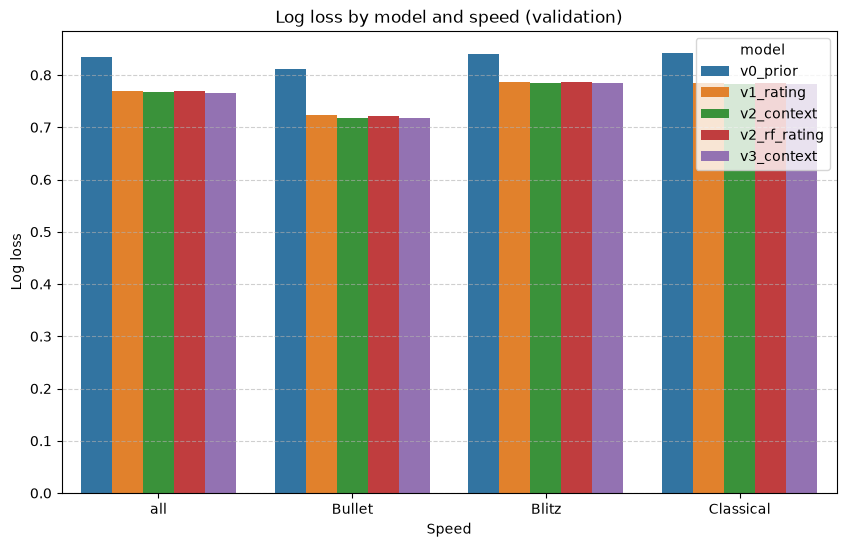

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=res,
    x="speed",
    y="log_loss",
    hue="model",
)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.title("Log loss by model and speed (validation)")
plt.xlabel("Speed")
plt.ylabel("Log loss")
plt.show()

In [26]:
res.round(4)

,model,speed,log_loss,brier,accuracy
0,v0_prior,all,0.8335,0.5373,0.4964
1,v0_prior,Bullet,0.8122,0.5299,0.4973
2,v0_prior,Blitz,0.8408,0.5399,0.4952
3,v0_prior,Classical,0.8420,0.5402,0.4976
4,v1_rating,all,0.7691,0.4805,0.6092
5,v1_rating,Bullet,0.7225,0.4515,0.6411
6,v1_rating,Blitz,0.7863,0.4918,0.5965
7,v1_rating,Classical,0.7852,0.4897,0.5995
8,v2_context,all,0.7668,0.4795,0.6104
9,v2_context,Bullet,0.7180,0.4495,0.6432


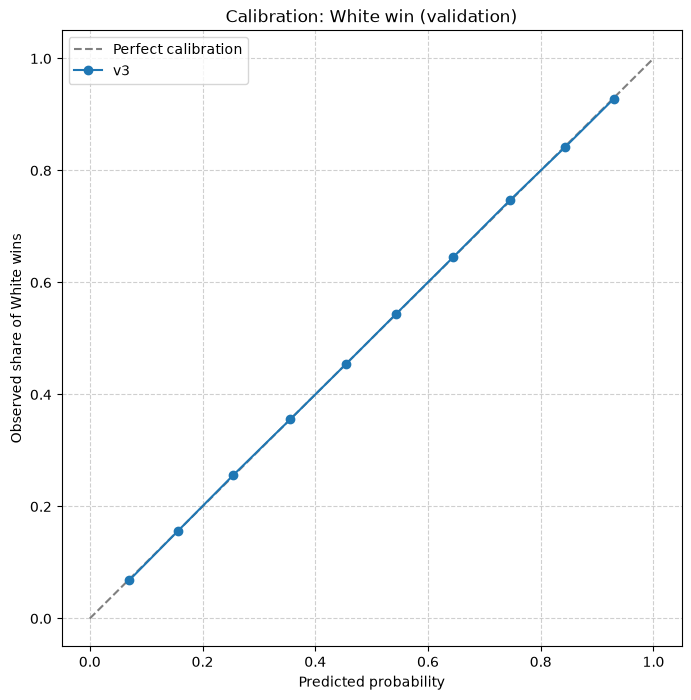

In [24]:
models = [("v3", proba_v3)]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

for name, proba in models:
    cal = calibration_table(proba[:, 2], y_valid, class_idx=2)
    plt.plot(cal["pred"], cal["observed"], "o-", label=name)

plt.grid(linestyle="--", alpha=0.6)
plt.title("Calibration: White win (validation)")
plt.xlabel("Predicted probability")
plt.ylabel("Observed share of White wins")
plt.legend()
plt.show()

## Results: v2 vs v3

**The opening adds even less.**
- Log loss: from 0.7668 (v2) to 0.7662 (v3), a 0.08% improvement.
- Brier: from 0.4795 (v2) to 0.4789 (v3).
- accuracy: from 61.04% (v2) to 61.14% (v3).
- ECO takes 4.1% of the gain, more than any other context feature, but improves validation log loss only slightly. Gain is measured on the training data, so a feature with many categories can collect gain without helping much on new games.

**v3 is well calibrated**
- across the whole range.

In [27]:
y_test = test["result"].to_numpy()

proba_test = {
    "v0_prior": np.tile(prior, (len(test), 1)),
    "v1_rating": model_v1.predict_proba(test[V1]),
    "v2_context": model_v2.predict_proba(test[V2]),
    "v3_opening": model_v3.predict_proba(test[V3]),
}

test_results = []
for name, proba in proba_test.items():
    test_results += evaluate(name, y_test, proba, test["speed"])

test_res = pd.DataFrame(test_results)
test_res.pivot(index="speed", columns="model", values="log_loss").round(4)

model,v0_prior,v1_rating,v2_context,v3_opening
speed,,,,
Blitz,0.8403,0.7867,0.7857,0.7851
Bullet,0.8111,0.7271,0.7222,0.7219
Classical,0.8413,0.7864,0.7846,0.7835
all,0.8327,0.7707,0.7684,0.7678


## Conclusion

The rating difference carries almost all predictable information about the result.
- Ratings alone improve log loss by 7.4% over the prior. The pre-game context adds 0.30% more, the opening another 0.08%.
- In the final model elo difference takes 91.9% of the gain, ECO 4.1%, average rating 1.3%.
- All LightGBM versions and the logistic regression are well calibrated, the random forest is not.

Before the game, and even after the opening, there is little to predict beyond the rating difference.
The remaining uncertainty lies in the game itself, which motivates 2nd project which includes features from the moves.